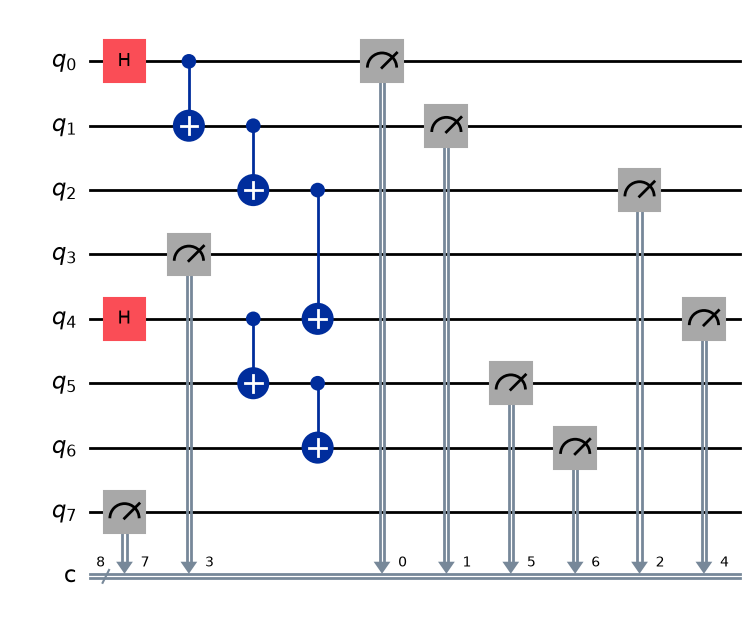

In [7]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt

qc = QuantumCircuit(8, 8)

# Module A
qc.h(0)
qc.cx(0, 1)
qc.cx(1, 2)

# Module B
qc.h(4)
qc.cx(4, 5)
qc.cx(5, 6)

# Inter-module operation
qc.cx(2, 4)

qc.measure(range(8), range(8))

qc.draw("mpl")

{'01100111': 2515, '01110000': 2532, '00000000': 2505, '00010111': 2448}


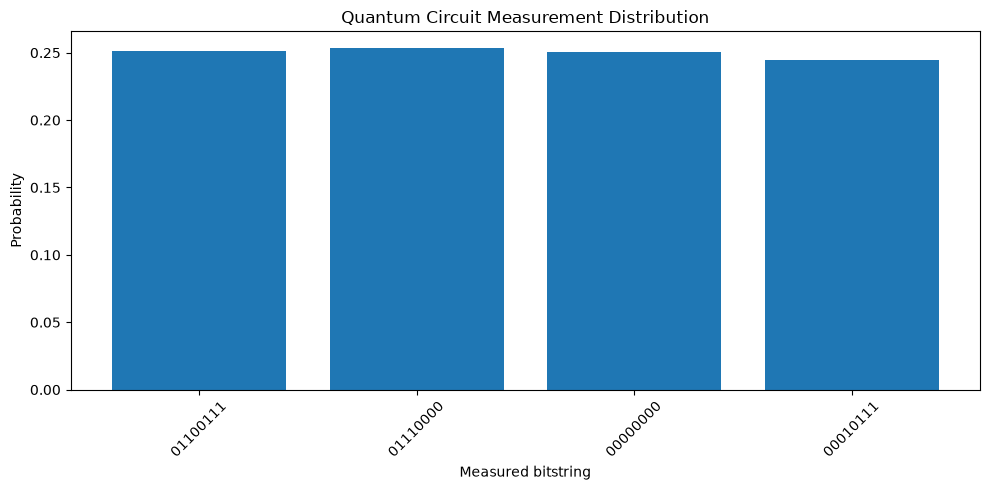

In [8]:
# -------------------------
# Run simulation
# -------------------------

sim = AerSimulator()

result = sim.run(
    qc,
    shots=10_000
).result()

counts = result.get_counts()

print(counts)


# -------------------------
# Convert counts → probabilities
# -------------------------

shots = sum(counts.values())

bitstrings = list(counts.keys())
probabilities = [
    counts[bitstring] / shots
    for bitstring in bitstrings
]


# -------------------------
# Plot
# -------------------------

plt.figure(figsize=(10, 5))

plt.bar(bitstrings, probabilities)

plt.xlabel("Measured bitstring")
plt.ylabel("Probability")
plt.title("Quantum Circuit Measurement Distribution")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()